# NLP CS60075 Assignment II, Project 9: Parameter-Efficient Fine-Tuning on IMDB

**Dataset assigned:** IMDB (`stanfordnlp/imdb`), 25,000 train / 25,000 test reviews, balanced.

| Section | What it does | Depends on | Approx. time (T4 GPU) |
|---|---|---|---|
| **0. Setup** | Drive mount, packages, config, helpers | nothing | 1 min |
| **D. Data** | Load + clean IMDB, fixed 22,500 / 2,500 train/holdout split | Section 0 | 1 to 2 min |
| **Task 1** | TF-IDF (word 1-2 grams, 20k features) + Random Forest (300 trees, depth 30, leaf 5) | 0, D | 5 to 10 min (CPU) |
| **Task 2** | LoRA on `bert-base-uncased`, ranks 4/8/16/32 + full fine-tuning reference | 0, D | about 25 min per LoRA rank, about 45 min full FT |
| **Task 3** | Logistic-regression meta-model on Task 1 + Task 2 probabilities, plus analysis | 0, D, saved Task 1 and Task 2 outputs | 1 min |
| Task 3 stretch (optional) | Joint TF-IDF + LoRA model trained end to end | 0, D, Task 1 vectorizer | about 30 min |

### How to run
1. `Runtime > Change runtime type > GPU`.
2. Run **Section 0** and **Section D** first in every new session. They are cheap and idempotent.
3. Run any task section on its own. Every task saves its outputs to Drive (`BASE_DIR/results`), and Task 3 only *loads* those files, so you can run Task 1 today, Task 2 tomorrow and Task 3 next week in three different sessions.
4. Task 2 resumes: a rank that already has saved results is skipped. Set `FORCE_RETRAIN = True` to redo it.
5. Want a 5-minute smoke test of the whole pipeline first? Set `QUICK_MODE = True` in Section 0. Quick-mode outputs go to a separate `results_quick` folder and never overwrite real results.

### Why there is a 2,500-review holdout
Task 3 trains a meta-model on the base models' predicted probabilities. If those probabilities come from reviews the base models were trained on, they're overconfident and the meta-model learns the wrong weights. So both base models are trained on the same **22,500** reviews, and the meta-model is trained on their predictions for the **2,500** held-out reviews that neither base model ever saw. The official 25,000-review test split is touched only for final numbers. Task 2 trains for a fixed 3 epochs and reports the final epoch (no checkpoint selection), so the holdout is only *monitored* during Task 2, never used to pick a model.

In [ ]:
# @title 0. Setup: Drive, packages, configuration, helpers
import os, sys, subprocess, importlib, importlib.util, json, time, gc, random, pickle, math, re, warnings, contextlib
warnings.filterwarnings("ignore")

# ---- install only what's missing (never upgrade preinstalled Colab packages mid-session:
#      that is what caused the old "partially initialized module 'datasets'" crash)
_needed = []
for _mod, _pkg in [("transformers", "transformers"), ("datasets", "datasets"), ("peft", "peft"),
                   ("sklearn", "scikit-learn"), ("scipy", "scipy"), ("matplotlib", "matplotlib"),
                   ("pandas", "pandas"), ("accelerate", "accelerate")]:
    if importlib.util.find_spec(_mod) is None:
        _needed.append(_pkg)
if _needed:
    print("Installing missing packages:", _needed)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_needed], check=False)

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
plt.style.use("grayscale")          # black-and-white figures, matching the report

# ---- Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print("Not running in Colab: outputs go to ./NLP_TermProject")

# If your team folder is a shared folder, add a shortcut to it in "My Drive" and point BASE_DIR at it.
BASE_DIR = "/content/drive/MyDrive/NLP_TermProject" if IN_COLAB else os.path.abspath("./NLP_TermProject")

# ---------------------------------------------------------------- configuration
SEED          = 42
QUICK_MODE    = False   # True = tiny subsample smoke test (2,000 train / 500 holdout / 1,000 test)
FORCE_RETRAIN = False   # True = ignore saved Task 2 results and retrain

HOLDOUT_SIZE  = 2500    # held out of the 25k train split for stacking (Task 3)
MODEL_NAME    = "bert-base-uncased"
MAX_LEN       = 512

# Task 1 (spec)
T1_NGRAM, T1_MAX_FEATURES = (1, 2), 20000
T1_RF = dict(n_estimators=300, max_depth=30, min_samples_leaf=5)
T1_FULL_REFERENCE = True    # also fit on the full 25k train split (spec-exact number, a few extra minutes)
RUN_T1_GRID       = False   # optional n-gram / feature-cap ablation, selected on the holdout (slow: 16 RF fits)

# Task 2 (spec)
LORA_RANKS        = [4, 8, 16, 32]   # alpha = 2r, dropout 0.1, query/value projections
LORA_LR, FULL_LR  = 3e-4, 2e-5
BATCH_SIZE        = 16
EPOCHS            = 3
WEIGHT_DECAY      = 0.01
FULL_FT_PHYS_BS   = 8        # full FT: 8 x 2 gradient accumulation = effective batch 16 (fits a 16 GB T4)
SAVE_FULL_FT_WEIGHTS = False # full FT weights are ~440 MB; probabilities are all Task 3 needs
RUN_STRETCH       = True    # Task 3 stretch: joint TF-IDF + LoRA model

if QUICK_MODE:
    LORA_RANKS, EPOCHS = [4, 8], 1

# ---------------------------------------------------------------- paths
SUB = "_quick" if QUICK_MODE else ""
DATA_DIR = os.path.join(BASE_DIR, "data")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints" + SUB)
RES_DIR  = os.path.join(BASE_DIR, "results" + SUB)
FIG_DIR  = os.path.join(RES_DIR, "figures")
for _d in (DATA_DIR, CKPT_DIR, RES_DIR, FIG_DIR):
    os.makedirs(_d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_bf16 = DEVICE.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8   # A100/L4: bf16; T4: fp16
AMP_DTYPE = torch.bfloat16 if _bf16 else torch.float16

# ---------------------------------------------------------------- helpers
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def res_path(name):
    return os.path.join(RES_DIR, name)

def save_json(obj, name):
    with open(res_path(name), "w") as f:
        json.dump(obj, f, indent=2)

def load_json(name):
    with open(res_path(name)) as f:
        return json.load(f)

def save_np(arr, name):
    np.save(res_path(name), np.asarray(arr))

def require(name, made_by):
    """Load a saved .npy/.json result, or fail with a message that says which task to run."""
    p = res_path(name)
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing {p}.\n  -> Run {made_by} first (it saves this file), then re-run this cell.")
    return np.load(p) if name.endswith(".npy") else load_json(name)

def autocast_ctx():
    if DEVICE.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=AMP_DTYPE)
    return contextlib.nullcontext()

def _scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

def accuracy(y, p1):
    return float(np.mean((np.asarray(p1) >= 0.5).astype(int) == np.asarray(y)))

set_seed()
print(f"torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)}, AMP {AMP_DTYPE})" if DEVICE.type == "cuda" else ""))
print("Results  ->", RES_DIR)
print("Checkpts ->", CKPT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.11.0+cu130 | device cuda (Tesla T4, AMP torch.float16)
Results  -> /content/drive/MyDrive/NLP_TermProject/results
Checkpts -> /content/drive/MyDrive/NLP_TermProject/checkpoints


## D. Data: load, clean, split (run second, every session)

* Source: `stanfordnlp/imdb` on the Hugging Face Hub. If the Hub is unreachable, the cell falls back to the original Stanford tarball automatically.
* Cleaning (Datasets doc, Section 9.3): leftover `<br />` tags replaced by spaces, whitespace collapsed.
* The 22,500 / 2,500 split of the train set is stratified, seeded, and saved to `data/split_indices.json` so every session and every task uses exactly the same reviews.
* The cleaned data is cached to Drive, so later sessions load it in seconds.

In [ ]:
# @title D. Load and split IMDB
from sklearn.model_selection import train_test_split

def clean_text(t):
    t = re.sub(r"<br\s*/?>", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def _from_hf():
    from datasets import load_dataset
    ds = load_dataset("stanfordnlp/imdb")
    tr = pd.DataFrame({"text": list(ds["train"]["text"]), "label": list(ds["train"]["label"])})
    te = pd.DataFrame({"text": list(ds["test"]["text"]),  "label": list(ds["test"]["label"])})
    return tr, te

def _from_stanford():
    import tarfile, urllib.request, glob
    tgz = os.path.join(DATA_DIR, "aclImdb_v1.tar.gz")
    if not os.path.exists(tgz):
        print("Downloading Stanford tarball...")
        urllib.request.urlretrieve("https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz", tgz)
    root = "/content/aclImdb" if IN_COLAB else os.path.join(DATA_DIR, "aclImdb")
    if not os.path.exists(root):
        with tarfile.open(tgz) as tf:
            tf.extractall(os.path.dirname(root))
    def read(split):
        rows = []
        for lab, sub in [(0, "neg"), (1, "pos")]:
            for fp in sorted(glob.glob(os.path.join(root, split, sub, "*.txt"))):
                with open(fp, encoding="utf-8") as f:
                    rows.append((f.read(), lab))
        return pd.DataFrame(rows, columns=["text", "label"])
    return read("train"), read("test")

def get_data():
    """Returns a dict with cleaned train/test frames and the fixed core/holdout index split."""
    global _DATA
    if "_DATA" in globals() and _DATA is not None:
        return _DATA
    tr_p, te_p = os.path.join(DATA_DIR, "imdb_train_clean.pkl"), os.path.join(DATA_DIR, "imdb_test_clean.pkl")
    if os.path.exists(tr_p) and os.path.exists(te_p):
        train_df, test_df = pd.read_pickle(tr_p), pd.read_pickle(te_p)
        print("Loaded cleaned IMDB from Drive cache.")
    else:
        try:
            train_df, test_df = _from_hf()
            print("Loaded IMDB from the Hugging Face Hub.")
        except Exception as e:
            print("HF Hub load failed (", type(e).__name__, "). Falling back to Stanford tarball.")
            train_df, test_df = _from_stanford()
        train_df["text"] = train_df["text"].map(clean_text)
        test_df["text"]  = test_df["text"].map(clean_text)
        train_df.to_pickle(tr_p); test_df.to_pickle(te_p)
    assert len(train_df) == 25000 and len(test_df) == 25000, "Unexpected IMDB size"

    split_p = os.path.join(DATA_DIR, "split_indices.json")
    if os.path.exists(split_p):
        with open(split_p) as f:
            sp = json.load(f)
        core_idx, hold_idx = np.array(sp["core"]), np.array(sp["holdout"])
    else:
        core_idx, hold_idx = train_test_split(np.arange(len(train_df)), test_size=HOLDOUT_SIZE,
                                              stratify=train_df["label"].values, random_state=SEED)
        core_idx, hold_idx = np.sort(core_idx), np.sort(hold_idx)
        with open(split_p, "w") as f:
            json.dump({"seed": SEED, "core": core_idx.tolist(), "holdout": hold_idx.tolist()}, f)
    test_idx = np.arange(len(test_df))

    if QUICK_MODE:
        rng = np.random.RandomState(SEED)
        core_idx = np.sort(rng.choice(core_idx, 2000, replace=False))
        hold_idx = np.sort(rng.choice(hold_idx, 500, replace=False))
        test_idx = np.sort(rng.choice(test_idx, 1000, replace=False))

    _DATA = dict(
        train_df=train_df, test_df=test_df,
        core_text=train_df["text"].values[core_idx].tolist(), y_core=train_df["label"].values[core_idx],
        hold_text=train_df["text"].values[hold_idx].tolist(), y_hold=train_df["label"].values[hold_idx],
        test_text=test_df["text"].values[test_idx].tolist(),  y_test=test_df["label"].values[test_idx],
        full_text=train_df["text"].tolist(), y_full=train_df["label"].values,
        core_idx=core_idx, hold_idx=hold_idx, test_idx=test_idx)
    return _DATA

_DATA = None
D = get_data()
print(f"core train {len(D['y_core'])} | holdout {len(D['y_hold'])} | test {len(D['y_test'])}")
print("label balance  core %.3f  holdout %.3f  test %.3f" % (D["y_core"].mean(), D["y_hold"].mean(), D["y_test"].mean()))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Loaded IMDB from the Hugging Face Hub.
core train 22500 | holdout 2500 | test 25000
label balance  core 0.500  holdout 0.500  test 0.500


## Task 1: Classical baseline, TF-IDF + Random Forest

Exactly the spec: TF-IDF over word 1-2 grams with `max_features = 20,000`, Random Forest with 300 trees, max depth 30, min samples per leaf 5. No pretrained model anywhere.

Two fits:
* **Stacking model** on the 22,500-review core split. Its holdout and test probabilities feed Task 3.
* **Spec-exact reference** on all 25,000 training reviews (`T1_FULL_REFERENCE`), so the headline Task 1 number matches the assignment wording exactly.

Metric: accuracy on the official IMDB test split.

- Contributed by (23EC10099) Avik Ghosh

In [ ]:
# @title Task 1: fit TF-IDF + Random Forest, save probabilities
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

D = get_data(); set_seed()

def fit_tfidf_rf(texts, labels, ngram=T1_NGRAM, max_features=T1_MAX_FEATURES):
    vec = TfidfVectorizer(ngram_range=ngram, max_features=max_features)
    X = vec.fit_transform(texts)
    rf = RandomForestClassifier(**T1_RF, n_jobs=-1, random_state=SEED)
    rf.fit(X, labels)
    return vec, rf

t0 = time.time()
vec, rf = fit_tfidf_rf(D["core_text"], D["y_core"])
p_hold = rf.predict_proba(vec.transform(D["hold_text"]))[:, 1]
p_test = rf.predict_proba(vec.transform(D["test_text"]))[:, 1]
t1_time = (time.time() - t0) / 60

save_np(p_hold, "t1_hold_prob.npy"); save_np(p_test, "t1_test_prob.npy")
with open(os.path.join(CKPT_DIR, "t1_tfidf_rf.pkl"), "wb") as f:
    pickle.dump((vec, rf), f)

t1 = {"config": {"ngram_range": list(T1_NGRAM), "max_features": T1_MAX_FEATURES, **T1_RF},
      "train_size": len(D["y_core"]),
      "holdout_acc": accuracy(D["y_hold"], p_hold),
      "test_acc": accuracy(D["y_test"], p_test),
      "minutes": round(t1_time, 2)}
print(f"[core model, {len(D['y_core'])} reviews] holdout acc {t1['holdout_acc']:.4f} | test acc {t1['test_acc']:.4f} | {t1_time:.1f} min")
print(classification_report(D["y_test"], (p_test >= 0.5).astype(int), target_names=["negative", "positive"], digits=4))
print("Confusion matrix (rows = gold neg/pos):\n", confusion_matrix(D["y_test"], (p_test >= 0.5).astype(int)))

if T1_FULL_REFERENCE:
    t0 = time.time()
    vec_f, rf_f = fit_tfidf_rf(D["full_text"], D["y_full"])
    p_full = rf_f.predict_proba(vec_f.transform(D["test_text"]))[:, 1]
    t1["full_train_test_acc"] = accuracy(D["y_test"], p_full)
    t1["full_train_minutes"] = round((time.time() - t0) / 60, 2)
    print(f"[spec-exact, full 25k train] test acc {t1['full_train_test_acc']:.4f}")
    del vec_f, rf_f

save_json(t1, "task1_results.json")
free_memory()

[core model, 22500 reviews] holdout acc 0.8528 | test acc 0.8439 | 2.4 min
              precision    recall  f1-score   support

    negative     0.8651    0.8150    0.8393     12500
    positive     0.8251    0.8729    0.8483     12500

    accuracy                         0.8439     25000
   macro avg     0.8451    0.8439    0.8438     25000
weighted avg     0.8451    0.8439    0.8438     25000

Confusion matrix (rows = gold neg/pos):
 [[10187  2313]
 [ 1589 10911]]
[spec-exact, full 25k train] test acc 0.8477


In [ ]:
# @title Task 1 (optional ablation): n-gram range x feature cap, chosen on the HOLDOUT, never on test
if RUN_T1_GRID:
    D = get_data(); rows = []
    for mf in [20000, 30000, 40000, 50000]:
        for ng in [(1, 1), (1, 2), (1, 3), (1, 5)]:
            v, m = fit_tfidf_rf(D["core_text"], D["y_core"], ngram=ng, max_features=mf)
            rows.append({"ngram": str(ng), "max_features": mf,
                         "holdout_acc": accuracy(D["y_hold"], m.predict_proba(v.transform(D["hold_text"]))[:, 1])})
            print(rows[-1]); del v, m; free_memory()
    grid = pd.DataFrame(rows).sort_values("holdout_acc", ascending=False)
    grid.to_csv(res_path("task1_grid_holdout.csv"), index=False)
    best = grid.iloc[0]
    print("Best on holdout:", dict(best))
    ng = tuple(int(x) for x in best["ngram"].strip("()").split(","))
    v, m = fit_tfidf_rf(D["core_text"], D["y_core"], ngram=ng, max_features=int(best["max_features"]))
    print("Its test accuracy:", accuracy(D["y_test"], m.predict_proba(v.transform(D["test_text"]))[:, 1]))
    display(grid)
else:
    print("Grid ablation skipped (RUN_T1_GRID = False).")

Grid ablation skipped (RUN_T1_GRID = False).


In [ ]:
# @title Task 1 results table
t1 = require("task1_results.json", "Task 1")
rows = [{"Model": "TF-IDF + RF (22.5k core, used for stacking)", "Test accuracy": t1["test_acc"]}]
if "full_train_test_acc" in t1:
    rows.insert(0, {"Model": "TF-IDF + RF (full 25k train, spec-exact)", "Test accuracy": t1["full_train_test_acc"]})
display(pd.DataFrame(rows).style.format({"Test accuracy": "{:.4f}"}).hide(axis="index"))

Model,Test accuracy
"TF-IDF + RF (full 25k train, spec-exact)",0.8477
"TF-IDF + RF (22.5k core, used for stacking)",0.8439


**Task 1 discussion.** A bag of word and bigram counts with a shallow forest gets roughly 85% of IMDB reviews right with zero pretraining (the earlier exploratory run logged 0.8477 for this exact configuration). Reviews are long, and sentiment words like *waste*, *worst*, *excellent*, *7/10* repeat inside them, so lexical features alone are strong. The errors that remain are mostly the classic hard cases for bags of n-grams: negation scope ("not bad at all"), contrastive reviews that praise the actors and pan the plot, and sarcasm. Depth-30 trees over 20k sparse features also underfit compared to a linear model on the same features, which is the price of following the spec's classifier choice.

## Task 2: Paper reproduction, LoRA (Hu et al., 2021, arXiv:2106.09685)

* Base: `bert-base-uncased` + sequence-classification head, all base weights frozen.
* LoRA on the **query** and **value** projections of all 12 layers, rank r in {4, 8, 16, 32}, alpha = 2r, LoRA dropout 0.1. The classifier head stays trainable (PEFT does this for `SEQ_CLS`).
* AdamW, lr 3e-4, batch 16, weight decay 0.01, 3 epochs, linear decay, gradient clipping at 1.0 (the HF Trainer default the earlier run used).
* Full fine-tuning reference: same checkpoint, lr 2e-5, effective batch 16 (8 x 2 accumulation), 3 epochs.
* Reviews truncated to 512 subwords; the first cell reports what fraction needed truncating (Datasets doc, Section 9.3).
* A hand-written PyTorch loop replaces `Trainer`, which removes the version-dependent argument names (`eval_strategy` vs `evaluation_strategy`, `tokenizer` vs `processing_class`) that broke the old notebook. Padding is dynamic and evaluation batches are length-sorted, which is much faster than padding every review to 512.

- Contributed by (26CD91R05) Ashutosh Kumar Barnwal

In [ ]:
# @title Task 2a: tokenizer and truncation statistics
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

D = get_data()
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def token_lengths(texts, bs=2000):
    out = []
    for i in range(0, len(texts), bs):
        out.extend(len(x) for x in tok(texts[i:i + bs], add_special_tokens=True, truncation=False)["input_ids"])
    return np.array(out)

len_train, len_test = token_lengths(D["full_text"]), token_lengths(D["test_text"])
save_np(len_test, "t2_test_token_lengths.npy")
trunc = {"max_len": MAX_LEN,
         "train_truncated_frac": float(np.mean(len_train > MAX_LEN)),
         "test_truncated_frac": float(np.mean(len_test > MAX_LEN)),
         "train_median_tokens": float(np.median(len_train)),
         "test_median_tokens": float(np.median(len_test))}
save_json(trunc, "t2_truncation.json")
print(f"Truncated to {MAX_LEN}: train {100*trunc['train_truncated_frac']:.1f}% | test {100*trunc['test_truncated_frac']:.1f}%")
print(f"Median length (subwords): train {trunc['train_median_tokens']:.0f} | test {trunc['test_median_tokens']:.0f}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Truncated to 512: train 13.3% | test 12.3%
Median length (subwords): train 222 | test 219


In [ ]:
# @title Task 2b: datasets, training loop, prediction (definitions only)
from torch.utils.data import Dataset, DataLoader, Subset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
from peft import LoraConfig, TaskType, get_peft_model
hf_logging.set_verbosity_error()

if "tok" not in globals():
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tok)

class EncDataset(Dataset):
    def __init__(self, texts, labels):
        enc = tok(texts, truncation=True, max_length=MAX_LEN)
        self.enc = {k: list(v) for k, v in enc.items()}
        self.labels = np.asarray(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.enc}
        item["labels"] = int(self.labels[i])
        return item

def get_t2_datasets():
    global _T2DS
    if "_T2DS" not in globals() or _T2DS is None:
        D = get_data()
        print("Tokenizing core / holdout / test ...")
        _T2DS = (EncDataset(D["core_text"], D["y_core"]), EncDataset(D["hold_text"], D["y_hold"]),
                 EncDataset(D["test_text"], D["y_test"]))
    return _T2DS
_T2DS = None

@torch.no_grad()
def predict_probs(model, ds, bs=64):
    """Positive-class probability for every example, in the dataset's original order."""
    model.eval()
    order = np.argsort([-len(x) for x in ds.enc["input_ids"]])     # long first: tight padding, early OOM signal
    dl = DataLoader(Subset(ds, order.tolist()), batch_size=bs, shuffle=False, collate_fn=collator)
    chunks = []
    for batch in dl:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        batch.pop("labels")
        with autocast_ctx():
            chunks.append(model(**batch).logits.float().cpu())
    logits = torch.cat(chunks)
    probs = torch.softmax(logits, dim=-1)[:, 1].numpy()
    out = np.empty_like(probs); out[order] = probs
    return out

def count_trainable(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

def train_classifier(tag, build_fn, lr, phys_bs, accum, save_fn=None):
    """Train a fixed number of epochs, report the FINAL epoch. Holdout is monitored only.
    Saves t2_<tag>_metrics.json, t2_<tag>_hold_prob.npy, t2_<tag>_test_prob.npy. Skips if they exist."""
    mpath = res_path(f"t2_{tag}_metrics.json")
    if not FORCE_RETRAIN and all(os.path.exists(res_path(f)) for f in
                                 [f"t2_{tag}_metrics.json", f"t2_{tag}_hold_prob.npy", f"t2_{tag}_test_prob.npy"]):
        m = load_json(f"t2_{tag}_metrics.json")
        print(f"[{tag}] found saved results (test acc {m['test_acc']:.4f}); skipping. Set FORCE_RETRAIN=True to redo.")
        return m

    train_ds, hold_ds, test_ds = get_t2_datasets()
    free_memory(); set_seed()
    model = build_fn().to(DEVICE)
    n_train = count_trainable(model)
    n_total = int(sum(p.numel() for p in model.parameters()))

    no_decay = ("bias", "LayerNorm.weight", "LayerNorm.bias")
    params = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    groups = [{"params": [p for n, p in params if not any(k in n for k in no_decay)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in params if any(k in n for k in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=lr)

    g = torch.Generator(); g.manual_seed(SEED)
    dl = DataLoader(train_ds, batch_size=phys_bs, shuffle=True, collate_fn=collator, generator=g, num_workers=2)
    updates_per_epoch = math.ceil(len(dl) / accum)
    sched = get_linear_schedule_with_warmup(opt, 0, updates_per_epoch * EPOCHS)
    scaler = _scaler(DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)

    history, t0 = [], time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); run_loss, seen = 0.0, 0
        opt.zero_grad(set_to_none=True)
        for step, batch in enumerate(dl):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with autocast_ctx():
                loss = model(**batch).loss / accum
            scaler.scale(loss).backward()
            if (step + 1) % accum == 0 or step + 1 == len(dl):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for _, p in params], 1.0)
                scaler.step(opt); scaler.update()
                opt.zero_grad(set_to_none=True); sched.step()
            run_loss += loss.item() * accum; seen += 1
            if step % 400 == 0:
                print(f"  [{tag}] epoch {ep} step {step}/{len(dl)} loss {run_loss/seen:.4f} ({(time.time()-t0)/60:.1f} min)")
        ph = predict_probs(model, hold_ds)
        eps = 1e-7
        hold_nll = float(-np.mean(hold_ds.labels * np.log(ph + eps) + (1 - hold_ds.labels) * np.log(1 - ph + eps)))
        history.append({"epoch": ep, "train_loss": run_loss / seen, "holdout_loss": hold_nll,
                        "holdout_acc": accuracy(hold_ds.labels, ph)})
        print(f"[{tag}] epoch {ep}: train loss {history[-1]['train_loss']:.4f} | "
              f"holdout loss {hold_nll:.4f} | holdout acc {history[-1]['holdout_acc']:.4f}")

    p_test = predict_probs(model, test_ds)
    save_np(ph, f"t2_{tag}_hold_prob.npy"); save_np(p_test, f"t2_{tag}_test_prob.npy")
    if save_fn is not None:
        save_fn(model, os.path.join(CKPT_DIR, tag))
    m = {"tag": tag, "trainable_params": n_train, "total_params": n_total,
         "trainable_pct": 100 * n_train / n_total, "lr": lr, "effective_batch": phys_bs * accum,
         "epochs": EPOCHS, "history": history, "holdout_acc": history[-1]["holdout_acc"],
         "test_acc": accuracy(test_ds.labels, p_test), "minutes": round((time.time() - t0) / 60, 1)}
    save_json(m, f"t2_{tag}_metrics.json")
    print(f"[{tag}] TEST ACC {m['test_acc']:.4f} | trainable {n_train:,} ({m['trainable_pct']:.4f}%) | {m['minutes']} min")
    del model, opt; free_memory()
    return m

def build_lora(r):
    def _b():
        base = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
        cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=r, lora_alpha=2 * r, lora_dropout=0.1,
                         target_modules=["query", "value"])
        m = get_peft_model(base, cfg); m.print_trainable_parameters()
        return m
    return _b

def build_full():
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

def save_adapter(model, path):
    model.save_pretrained(path)        # LoRA: saves only the adapter + head (a few MB)

print("Task 2 definitions ready.")

Task 2 definitions ready.


In [ ]:
# Fix: Colab ships torchao 0.10, which PEFT rejects. This project doesn't use torchao, so remove it.
import importlib, importlib.util, importlib.metadata as md
from packaging.version import parse
if importlib.util.find_spec("torchao") is not None and parse(md.version("torchao")) < parse("0.16.0"):
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
    for k in [k for k in sys.modules if k == "torchao" or k.startswith("torchao.")]:
        del sys.modules[k]
    importlib.invalidate_caches()
    print("Removed incompatible torchao.")
else:
    print("torchao OK (absent or new enough).")

Removed incompatible torchao.


In [ ]:
# @title Task 2c: train LoRA for every rank (resumable)
lora_metrics = {}
for r in LORA_RANKS:
    print(f"\n========== LoRA rank {r} ==========")
    lora_metrics[r] = train_classifier(f"lora_r{r}", build_lora(r), LORA_LR, BATCH_SIZE, 1, save_fn=save_adapter)


========== LoRA rank 4 ==========
Tokenizing core / holdout / test ...


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

trainable params: 148,994 || all params: 109,632,772 || trainable%: 0.1359
  [lora_r4] epoch 1 step 0/1407 loss 0.6783 (0.0 min)
  [lora_r4] epoch 1 step 400/1407 loss 0.3679 (2.1 min)
  [lora_r4] epoch 1 step 800/1407 loss 0.3118 (4.4 min)
  [lora_r4] epoch 1 step 1200/1407 loss 0.2867 (6.7 min)
[lora_r4] epoch 1: train loss 0.2778 | holdout loss 0.2281 | holdout acc 0.9172
  [lora_r4] epoch 2 step 0/1407 loss 0.2429 (8.1 min)
  [lora_r4] epoch 2 step 400/1407 loss 0.2102 (10.3 min)
  [lora_r4] epoch 2 step 800/1407 loss 0.2113 (12.6 min)
  [lora_r4] epoch 2 step 1200/1407 loss 0.2053 (14.9 min)
[lora_r4] epoch 2: train loss 0.2052 | holdout loss 0.2319 | holdout acc 0.9160
  [lora_r4] epoch 3 step 0/1407 loss 0.5042 (16.3 min)
  [lora_r4] epoch 3 step 400/1407 loss 0.1880 (18.5 min)
  [lora_r4] epoch 3 step 800/1407 loss 0.1837 (20.8 min)
  [lora_r4] epoch 3 step 1200/1407 loss 0.1816 (23.1 min)
[lora_r4] epoch 3: train loss 0.1821 | holdout loss 0.2306 | holdout acc 0.9212
[lora_r4]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

trainable params: 296,450 || all params: 109,780,228 || trainable%: 0.2700
  [lora_r8] epoch 1 step 0/1407 loss 0.6783 (0.0 min)
  [lora_r8] epoch 1 step 400/1407 loss 0.3487 (2.3 min)
  [lora_r8] epoch 1 step 800/1407 loss 0.3001 (4.6 min)
  [lora_r8] epoch 1 step 1200/1407 loss 0.2778 (6.8 min)
[lora_r8] epoch 1: train loss 0.2700 | holdout loss 0.2246 | holdout acc 0.9188
  [lora_r8] epoch 2 step 0/1407 loss 0.2457 (8.2 min)
  [lora_r8] epoch 2 step 400/1407 loss 0.2024 (10.4 min)
  [lora_r8] epoch 2 step 800/1407 loss 0.2043 (12.7 min)
  [lora_r8] epoch 2 step 1200/1407 loss 0.1984 (15.0 min)
[lora_r8] epoch 2: train loss 0.1976 | holdout loss 0.2366 | holdout acc 0.9188
  [lora_r8] epoch 3 step 0/1407 loss 0.4687 (16.3 min)
  [lora_r8] epoch 3 step 400/1407 loss 0.1741 (18.6 min)
  [lora_r8] epoch 3 step 800/1407 loss 0.1697 (20.8 min)
  [lora_r8] epoch 3 step 1200/1407 loss 0.1674 (23.1 min)
[lora_r8] epoch 3: train loss 0.1685 | holdout loss 0.2379 | holdout acc 0.9196
[lora_r8]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

trainable params: 591,362 || all params: 110,075,140 || trainable%: 0.5372
  [lora_r16] epoch 1 step 0/1407 loss 0.6783 (0.0 min)
  [lora_r16] epoch 1 step 400/1407 loss 0.3419 (2.3 min)
  [lora_r16] epoch 1 step 800/1407 loss 0.2954 (4.5 min)
  [lora_r16] epoch 1 step 1200/1407 loss 0.2744 (6.8 min)
[lora_r16] epoch 1: train loss 0.2669 | holdout loss 0.2076 | holdout acc 0.9196
  [lora_r16] epoch 2 step 0/1407 loss 0.2088 (8.2 min)
  [lora_r16] epoch 2 step 400/1407 loss 0.1932 (10.4 min)
  [lora_r16] epoch 2 step 800/1407 loss 0.1953 (12.7 min)
  [lora_r16] epoch 2 step 1200/1407 loss 0.1891 (15.0 min)
[lora_r16] epoch 2: train loss 0.1885 | holdout loss 0.2298 | holdout acc 0.9212
  [lora_r16] epoch 3 step 0/1407 loss 0.4410 (16.3 min)
  [lora_r16] epoch 3 step 400/1407 loss 0.1591 (18.6 min)
  [lora_r16] epoch 3 step 800/1407 loss 0.1545 (20.8 min)
  [lora_r16] epoch 3 step 1200/1407 loss 0.1519 (23.1 min)
[lora_r16] epoch 3: train loss 0.1527 | holdout loss 0.2316 | holdout acc 0

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

trainable params: 1,181,186 || all params: 110,664,964 || trainable%: 1.0674
  [lora_r32] epoch 1 step 0/1407 loss 0.6783 (0.0 min)
  [lora_r32] epoch 1 step 400/1407 loss 0.3393 (2.3 min)
  [lora_r32] epoch 1 step 800/1407 loss 0.2934 (4.6 min)
  [lora_r32] epoch 1 step 1200/1407 loss 0.2730 (6.8 min)
[lora_r32] epoch 1: train loss 0.2654 | holdout loss 0.2071 | holdout acc 0.9200
  [lora_r32] epoch 2 step 0/1407 loss 0.1854 (8.2 min)
  [lora_r32] epoch 2 step 400/1407 loss 0.1857 (10.5 min)
  [lora_r32] epoch 2 step 800/1407 loss 0.1881 (12.7 min)
  [lora_r32] epoch 2 step 1200/1407 loss 0.1820 (15.0 min)
[lora_r32] epoch 2: train loss 0.1803 | holdout loss 0.2400 | holdout acc 0.9164
  [lora_r32] epoch 3 step 0/1407 loss 0.4028 (16.4 min)
  [lora_r32] epoch 3 step 400/1407 loss 0.1433 (18.6 min)
  [lora_r32] epoch 3 step 800/1407 loss 0.1372 (20.9 min)
  [lora_r32] epoch 3 step 1200/1407 loss 0.1353 (23.2 min)
[lora_r32] epoch 3: train loss 0.1364 | holdout loss 0.2391 | holdout acc

In [ ]:
# @title Task 2d: full fine-tuning reference (resumable)
full_metrics = train_classifier("full_ft", build_full, FULL_LR, FULL_FT_PHYS_BS, BATCH_SIZE // FULL_FT_PHYS_BS,
                                save_fn=(lambda m, p: m.save_pretrained(p)) if SAVE_FULL_FT_WEIGHTS else None)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  [full_ft] epoch 1 step 0/2813 loss 0.6168 (0.0 min)
  [full_ft] epoch 1 step 400/2813 loss 0.3628 (1.5 min)
  [full_ft] epoch 1 step 800/2813 loss 0.3267 (3.0 min)
  [full_ft] epoch 1 step 1200/2813 loss 0.2984 (4.4 min)
  [full_ft] epoch 1 step 1600/2813 loss 0.2784 (5.8 min)
  [full_ft] epoch 1 step 2000/2813 loss 0.2678 (7.2 min)
  [full_ft] epoch 1 step 2400/2813 loss 0.2580 (8.6 min)
  [full_ft] epoch 1 step 2800/2813 loss 0.2510 (9.9 min)
[full_ft] epoch 1: train loss 0.2513 | holdout loss 0.1980 | holdout acc 0.9296
  [full_ft] epoch 2 step 0/2813 loss 0.0314 (10.2 min)
  [full_ft] epoch 2 step 400/2813 loss 0.1288 (11.5 min)
  [full_ft] epoch 2 step 800/2813 loss 0.1367 (12.9 min)
  [full_ft] epoch 2 step 1200/2813 loss 0.1378 (14.3 min)
  [full_ft] epoch 2 step 1600/2813 loss 0.1382 (15.7 min)
  [full_ft] epoch 2 step 2000/2813 loss 0.1344 (17.0 min)
  [full_ft] epoch 2 step 2400/2813 loss 0.1360 (18.4 min)
  [full_ft] epoch 2 step 2800/2813 loss 0.1346 (19.8 min)
[full_ft] 

Model,Trainable params,% of total,Holdout acc,Test acc,Minutes
LoRA r=4,"148,994",0.1359,0.9212,0.9292,26.200000
LoRA r=8,"296,450",0.2700,0.9196,0.9327,26.300000
LoRA r=16,"591,362",0.5372,0.9272,0.9351,26.300000
LoRA r=32,"1,181,186",1.0674,0.9288,0.9369,26.300000
Full fine-tuning,"109,483,778",100.0000,0.9324,0.9393,31.500000


Best LoRA rank (by holdout accuracy): r=32


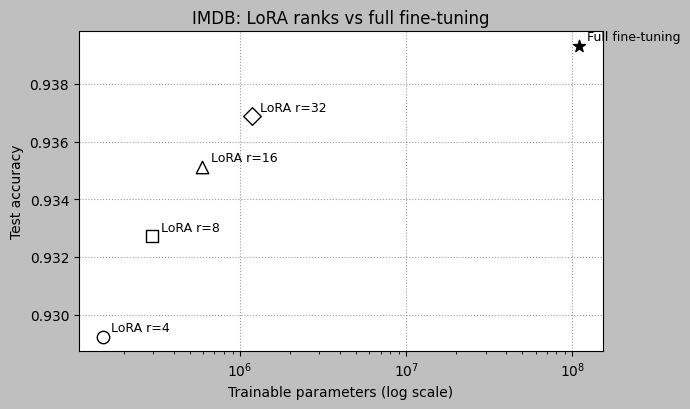

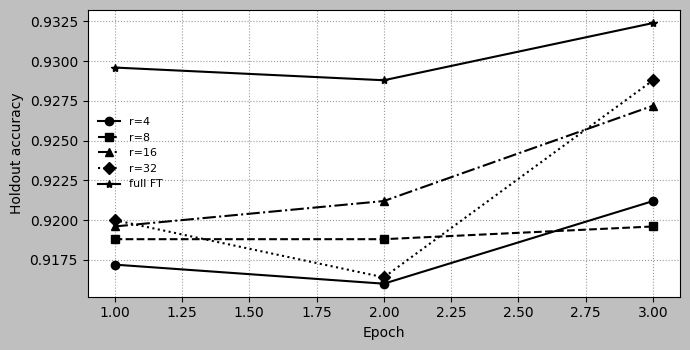

In [ ]:
# @title Task 2e: results table + trainable-parameters vs accuracy plot
rows = []
for r in LORA_RANKS:
    m = require(f"t2_lora_r{r}_metrics.json", f"Task 2c (rank {r})")
    rows.append({"Model": f"LoRA r={r}", "rank": r, "Trainable params": m["trainable_params"],
                 "% of total": m["trainable_pct"], "Holdout acc": m["holdout_acc"],
                 "Test acc": m["test_acc"], "Minutes": m["minutes"]})
fm = require("t2_full_ft_metrics.json", "Task 2d")
rows.append({"Model": "Full fine-tuning", "rank": None, "Trainable params": fm["trainable_params"],
             "% of total": fm["trainable_pct"], "Holdout acc": fm["holdout_acc"],
             "Test acc": fm["test_acc"], "Minutes": fm["minutes"]})
t2 = pd.DataFrame(rows)
t2.to_csv(res_path("task2_results.csv"), index=False)

lora_rows = t2[t2["rank"].notna()]
best = lora_rows.sort_values(["Holdout acc", "rank"], ascending=[False, True]).iloc[0]   # chosen on HOLDOUT
save_json({"best_rank": int(best["rank"]), "selected_by": "holdout accuracy",
           "rows": t2.drop(columns=["rank"]).to_dict(orient="records")}, "t2_summary.json")
display(t2.drop(columns=["rank"]).style.format({"Trainable params": "{:,}", "% of total": "{:.4f}",
        "Holdout acc": "{:.4f}", "Test acc": "{:.4f}"}).hide(axis="index"))
print(f"Best LoRA rank (by holdout accuracy): r={int(best['rank'])}")

fig, ax = plt.subplots(figsize=(7, 4.2))
markers = ["o", "s", "^", "D", "*"]
for i, row in t2.iterrows():
    ax.scatter(row["Trainable params"], row["Test acc"], s=80, color="black",
               marker=markers[i % len(markers)], facecolors="white" if i < len(t2) - 1 else "black")
    ax.annotate(row["Model"], (row["Trainable params"], row["Test acc"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Trainable parameters (log scale)"); ax.set_ylabel("Test accuracy")
ax.set_title("IMDB: LoRA ranks vs full fine-tuning"); ax.grid(True, linestyle=":", color="0.6")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task2_param_efficiency.pdf")); plt.savefig(os.path.join(FIG_DIR, "task2_param_efficiency.png"), dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
styles = ["-", "--", "-.", ":", "-"]
for i, r in enumerate(LORA_RANKS + ["full_ft"]):
    m = require(f"t2_lora_r{r}_metrics.json" if r != "full_ft" else "t2_full_ft_metrics.json", "Task 2")
    ax.plot([h["epoch"] for h in m["history"]], [h["holdout_acc"] for h in m["history"]], styles[i],
            color="black", marker=markers[i], label=f"r={r}" if r != "full_ft" else "full FT")
ax.set_xlabel("Epoch"); ax.set_ylabel("Holdout accuracy"); ax.legend(frameon=False, fontsize=8)
ax.grid(True, linestyle=":", color="0.6"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "task2_holdout_curves.pdf")); plt.show()

In [ ]:
# @title Task 2f: qualitative examples (best rank), most confident errors and correct calls
D = get_data()
best_rank = require("t2_summary.json", "Task 2e")["best_rank"]
p = require(f"t2_lora_r{best_rank}_test_prob.npy", "Task 2c")
y = D["y_test"]; pred = (p >= 0.5).astype(int); conf = np.abs(p - 0.5)
ex = pd.DataFrame({"text": [t[:350] + ("..." if len(t) > 350 else "") for t in D["test_text"]],
                   "gold": y, "pred": pred, "p_pos": p.round(4), "confidence": conf})
wrong = ex[ex.gold != ex.pred].sort_values("confidence", ascending=False).head(5)
right = ex[ex.gold == ex.pred].sort_values("confidence", ascending=True).head(3)
pd.concat([wrong.assign(kind="confident error"), right.assign(kind="correct but unsure")]).to_csv(
    res_path("task2_qualitative.csv"), index=False)
pd.set_option("display.max_colwidth", 350)
print(f"LoRA r={best_rank}: {int((pred != y).sum())} test errors")
display(wrong); display(right)

LoRA r=32: 1578 test errors


,text,gold,pred,p_pos,confidence
12061,"This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnificent. He is such a beautiful man and a very talented actor. And seeing most of Johnny's m...",0,1,0.9990,0.499034
9543,"Lois Weber's film ""Hypocrites"" was and still kind of is a very bold and daring film. I enjoyed it and was very impressed by the filming and story of it. The priest sees the hypocrisy of the people in his church and tries to show them the ""naked"" truth. The people are appalled when he reveals the naked statue portraying truth, after failing to l...",0,1,0.9990,0.499028
7063,"I finally rented this video after searching for it for many months. Initially I only wanted to see it because I'm an out and out Neil Pearson fan (Patrick, boyfriend of Isobel, the lead). However, the movie stands up very well without Neil (although he handles himself very well in this movie, he is overshadowed by the three main female characte...",0,1,0.9990,0.498988
3757,"I went to see this 3 nights ago here in Cork, Ireland. It was the world premiere of it, in the tiny cinema in the Triskel Arts Centre as part of the Cork Film Festival. I found ""Strange Fruit"" to be an excellent movie. It is a bit rough around the edges, but for a low-budget movie that is to be expected! In general the acting (particularly from...",0,1,0.9990,0.498982
8181,"The movie was a pleasure to watch if you are a fan of the Stooges. The story is told from the point of view of Moe Howard and his relationships with his brothers Shemp and Jerome (Curly) Howard, also the life long friendship with Larry Fine. The movie deals mostly with the off camera high points and pit falls of the Stooges multi decade career....",0,1,0.9989,0.498916


,text,gold,pred,p_pos,confidence
24159,"After seeing the trailer it was an easy decision not to see this film. I mean, I don't care for stupid ""stoner comedies."" I'm sure it was also an easy choice for a lot of people to get together, smoke a bowl and go check out this flick with the guy from The Simpsons and some guy named ""Billy Bob."" Should have been a good time, but the film's ju...",1,1,0.5000,0.000046
15726,"Watching this hilariously retro but very entertaining career girl tale, I was floored by Joan Crawford's first appearance. All I could think initially was, ""My God, it's the same face as Michael Jackson in his notorious booking photo!"" About 34 minutes into the movie, Diane Baker and Hope Lange get out of a cab in Greenwich Village. As they wal...",1,1,0.5022,0.002228
21145,"Bud Abbott and Lou Costello always had a good following among children, but in their careers I think you could say that they only made one film that could be designated for kids. Jack and the Beanstalk was that one film. It was part of a two picture independent deal from Warner Brothers, the second film being Abbott and Costello Meet Captain Ki...",1,1,0.5031,0.003082


**Task 2 discussion.** In the earlier exploratory run (full 25k train, same hyperparameters) LoRA reached 0.9318 / 0.9340 / 0.9378 / 0.9375 for r = 4 / 8 / 16 / 32 while training 0.14% to 1.07% of the weights, and full fine-tuning reached 0.9429 with 100%. So LoRA at r = 16 closes about 95% of the gap between the TF-IDF baseline and full fine-tuning, (0.9378 - 0.8477) / (0.9429 - 0.8477) = 0.946, while training 1/185th as many parameters. Accuracy flattens past r = 16, which matches the paper's claim that the useful weight update for a downstream task has low intrinsic rank. Full FT still wins by about half a point, and its holdout loss rises in epoch 3 while accuracy keeps climbing, a sign it's starting to overfit. The paper reports GLUE/SST-2 numbers rather than IMDB, so the comparison with the paper is about the *shape* of the curve (near-full-FT accuracy at tiny r) rather than an exact number.

## Task 3: Combine and improve, stacked meta-model

* Inputs: Task 1's RF probability and the best-rank LoRA probability (best rank picked by **holdout** accuracy, not test accuracy). Both are converted to log-odds, the natural scale for logistic regression. A raw-probability variant is reported too.
* Meta-model: logistic regression, fit on the **2,500 holdout reviews**. Neither base model saw these reviews, so the meta-model learns how much to trust each model on unseen text.
* Evaluated once on the 25,000 test reviews, alongside Task 1, Task 2 and a plain probability average.
* Extra analysis: paired bootstrap confidence interval and McNemar test for Task 3 vs Task 2, disagreement breakdown, accuracy on reviews longer than 512 subwords (where BERT is truncated but TF-IDF sees the full text), and qualitative examples.

This cell only loads files saved by Tasks 1 and 2, so it runs in a fresh session after Sections 0 and D.

- Contributed by (22CS30019) Darapu Adhithya Shiva Kumar Reddy

In [ ]:
# @title Task 3a: fit the meta-model on the holdout, evaluate on test
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from scipy.stats import binomtest

D = get_data(); set_seed()
y_hold, y_test = D["y_hold"], D["y_test"]
best_rank = require("t2_summary.json", "Task 2e")["best_rank"]
rf_h, rf_t = require("t1_hold_prob.npy", "Task 1"), require("t1_test_prob.npy", "Task 1")
lo_h, lo_t = require(f"t2_lora_r{best_rank}_hold_prob.npy", "Task 2c"), require(f"t2_lora_r{best_rank}_test_prob.npy", "Task 2c")
assert len(rf_h) == len(lo_h) == len(y_hold) and len(rf_t) == len(lo_t) == len(y_test), \
    "Task 1/2 outputs were made with a different QUICK_MODE setting. Re-run them with the current setting."

def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps); return np.log(p / (1 - p))

F_h, F_t = np.column_stack([logit(rf_h), logit(lo_h)]), np.column_stack([logit(rf_t), logit(lo_t)])
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
meta = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
cv_acc = cross_val_score(meta, F_h, y_hold, cv=cv, scoring="accuracy")
meta.fit(F_h, y_hold)
p_meta = meta.predict_proba(F_t)[:, 1]

meta_raw = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED).fit(np.column_stack([rf_h, lo_h]), y_hold)
p_meta_raw = meta_raw.predict_proba(np.column_stack([rf_t, lo_t]))[:, 1]
p_avg = (rf_t + lo_t) / 2
save_np(p_meta, "t3_test_prob.npy")

# paired bootstrap (Task 3 minus Task 2) and exact McNemar test
c_meta, c_lora = (p_meta >= .5) == y_test, (lo_t >= .5) == y_test
rng = np.random.RandomState(SEED)
boots = [np.mean(c_meta[i]) - np.mean(c_lora[i]) for i in (rng.randint(0, len(y_test), len(y_test)) for _ in range(2000))]
b, c = int(np.sum(c_meta & ~c_lora)), int(np.sum(~c_meta & c_lora))
mcnemar_p = float(binomtest(b, b + c, 0.5).pvalue) if b + c > 0 else 1.0

t3 = {"best_rank": best_rank, "meta_features": ["logit(p_rf)", "logit(p_lora)"],
      "coef_rf": float(meta.coef_[0][0]), "coef_lora": float(meta.coef_[0][1]), "intercept": float(meta.intercept_[0]),
      "holdout_cv_acc_mean": float(cv_acc.mean()), "holdout_cv_acc_std": float(cv_acc.std()),
      "t1_test_acc": accuracy(y_test, rf_t), "t2_test_acc": accuracy(y_test, lo_t),
      "t3_test_acc": accuracy(y_test, p_meta), "t3_raw_prob_test_acc": accuracy(y_test, p_meta_raw),
      "avg_prob_test_acc": accuracy(y_test, p_avg),
      "delta_t3_minus_t2": float(np.mean(c_meta) - np.mean(c_lora)),
      "delta_ci95": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))],
      "mcnemar_meta_only_right": b, "mcnemar_lora_only_right": c, "mcnemar_p": mcnemar_p}
save_json(t3, "task3_results.json")
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in t3.items()}, indent=1))

{
 "best_rank": 32,
 "meta_features": [
  "logit(p_rf)",
  "logit(p_lora)"
 ],
 "coef_rf": 1.7961,
 "coef_lora": 0.4995,
 "intercept": -0.0269,
 "holdout_cv_acc_mean": 0.9292,
 "holdout_cv_acc_std": 0.0095,
 "t1_test_acc": 0.8439,
 "t2_test_acc": 0.9369,
 "t3_test_acc": 0.9394,
 "t3_raw_prob_test_acc": 0.9374,
 "avg_prob_test_acc": 0.9372,
 "delta_t3_minus_t2": 0.0026,
 "delta_ci95": [
  0.0013189999999999897,
  0.003960000000000075
 ],
 "mcnemar_meta_only_right": 175,
 "mcnemar_lora_only_right": 111,
 "mcnemar_p": 0.0002
}


In [ ]:
# @title Task 3b: where do the models disagree? Long reviews, qualitative examples
D = get_data(); t3 = require("task3_results.json", "Task 3a")
rf_t = require("t1_test_prob.npy", "Task 1")
lo_t = require(f"t2_lora_r{t3['best_rank']}_test_prob.npy", "Task 2c")
p_meta = require("t3_test_prob.npy", "Task 3a")
y = D["y_test"]
if os.path.exists(res_path("t2_test_token_lengths.npy")):
    lens = np.load(res_path("t2_test_token_lengths.npy"))
else:
    from transformers import AutoTokenizer
    _tk = AutoTokenizer.from_pretrained(MODEL_NAME)
    lens = np.array([len(x) for x in _tk(D["test_text"], truncation=False)["input_ids"]])

pr, pl, pm = (rf_t >= .5).astype(int), (lo_t >= .5).astype(int), (p_meta >= .5).astype(int)
dis = pr != pl
breakdown = pd.DataFrame([
    {"Subset": "all test reviews", "n": len(y), "RF": np.mean(pr == y), "LoRA": np.mean(pl == y), "Meta": np.mean(pm == y)},
    {"Subset": f"<= {MAX_LEN} subwords", "n": int(np.sum(lens <= MAX_LEN)), "RF": np.mean((pr == y)[lens <= MAX_LEN]),
     "LoRA": np.mean((pl == y)[lens <= MAX_LEN]), "Meta": np.mean((pm == y)[lens <= MAX_LEN])},
    {"Subset": f"> {MAX_LEN} subwords (BERT truncated)", "n": int(np.sum(lens > MAX_LEN)), "RF": np.mean((pr == y)[lens > MAX_LEN]),
     "LoRA": np.mean((pl == y)[lens > MAX_LEN]), "Meta": np.mean((pm == y)[lens > MAX_LEN])},
    {"Subset": "RF and LoRA disagree", "n": int(dis.sum()), "RF": np.mean((pr == y)[dis]),
     "LoRA": np.mean((pl == y)[dis]), "Meta": np.mean((pm == y)[dis])}])
breakdown.to_csv(res_path("task3_breakdown.csv"), index=False)
t3.update({"n_long": int(np.sum(lens > MAX_LEN)),
           "long_rf": float(breakdown.iloc[2]["RF"]), "long_lora": float(breakdown.iloc[2]["LoRA"]), "long_meta": float(breakdown.iloc[2]["Meta"]),
           "n_disagree": int(dis.sum()), "dis_rf": float(breakdown.iloc[3]["RF"]), "dis_lora": float(breakdown.iloc[3]["LoRA"]),
           "dis_meta": float(breakdown.iloc[3]["Meta"])})
save_json(t3, "task3_results.json")
display(breakdown.style.format({"RF": "{:.4f}", "LoRA": "{:.4f}", "Meta": "{:.4f}"}).hide(axis="index"))

ex = pd.DataFrame({"text": [t[:350] + ("..." if len(t) > 350 else "") for t in D["test_text"]], "gold": y,
                   "p_rf": rf_t.round(3), "p_lora": lo_t.round(3), "p_meta": p_meta.round(3), "tokens": lens})
fixed  = ex[(pl != y) & (pm == y)].assign(kind="meta fixed a LoRA error").head(4)
broken = ex[(pl == y) & (pm != y)].assign(kind="meta broke a LoRA-correct call").head(4)
pd.concat([fixed, broken]).to_csv(res_path("task3_qualitative.csv"), index=False)
print(f"Meta fixed {int(((pl != y) & (pm == y)).sum())} LoRA errors and broke {int(((pl == y) & (pm != y)).sum())} LoRA-correct calls.")
pd.set_option("display.max_colwidth", 350); display(fixed); display(broken)

Subset,n,RF,LoRA,Meta
all test reviews,25000,0.8439,0.9369,0.9394
<= 512 subwords,21914,0.8448,0.9405,0.9430
> 512 subwords (BERT truncated),3086,0.8377,0.9109,0.9145
RF and LoRA disagree,3678,0.1841,0.8159,0.8336


Meta fixed 175 LoRA errors and broke 111 LoRA-correct calls.


,text,gold,p_rf,p_lora,p_meta,tokens,kind
148,"First of all, I wasn't sure who this film was aimed at - it seemed like a story for kids but had stuff in it kids wouldn't understand and find boring. There wasn't really much to it, Bruce Willis wasn't stretched as an actor at all. He did a lot of glancing to the side with that half smile of his - unless you are a big fan of his I wouldn't bot...",0,0.392,0.757,0.438,144,meta fixed a LoRA error
368,"The people who bash this movie were looking for it to be as cool and slick as the first one, which this isn't. This movie was supposed to be the complete opposite as Ocean's 11. This has been said by a lot of the cast members and also the director, Steven Soderbergh. Ocean's 12, while it did lack a gripping plot, is being bashed because it was ...",0,0.420,0.593,0.396,167,meta fixed a LoRA error
592,"I thought this movie was going to be a disgrace to the series. After all, part 3 didn't measure up to part 2, and this one doesn't have Daniel Sawn. Miyagi's humour wasn't quite as witty in this one as in part 3, but it was funny enough to make the movie worth watching. The girl's part was pretty good. She's a lost teenager who needs direction....",0,0.379,0.788,0.435,349,meta fixed a LoRA error
608,"I struggle to see the point of this movie. It is supposed to be a comedy but I didn't laugh once. The storyline is one that could have been interesting in a well made movie, but since this is acted by comics, the result is totally unbelievable (as comedies should be). The Comic strip series was very hit and miss, even withing the episodes, and ...",0,0.356,0.864,0.458,208,meta fixed a LoRA error


,text,gold,p_rf,p_lora,p_meta,tokens,kind
114,An obvious vanity press for Julie in her first movie with Blake. Let's see. Where do we begin. She is a traitor during a world war; she redeems that by falling in love; her friends (who are presumably patriots because they are German citizens) are expendable and must die; and she winds up as a heroine. OK. The scenes with the drunken pilot and ...,0,0.578,0.277,0.514,173,meta broke a LoRA-correct call
132,This movie should have been billed as three movie-summaries linked together to form a full-length feature film (including lots of shots of people slowly walking down dark corridors and streets). BE WARNED! The first hour of this movie is simply a re-hash of the first two Aztec movies as told by the main character. The actual movie doesn't start...,0,0.566,0.333,0.525,249,meta broke a LoRA-correct call
202,"An interesting period picec showing us what was amazing in 1938. Gosh, Ma, a fake accident ring suing for $25,000!!! I guess projected into the 21st century it would amount to a lot of money. The acting would amount to pure 21st century ham. Nice to see the president as a hard-working newcomer.",0,0.550,0.407,0.536,72,meta broke a LoRA-correct call
318,I hope this group of film-makers never re-unites.,0,0.624,0.375,0.651,16,meta broke a LoRA-correct call


Model,Test accuracy
Task 1: TF-IDF + RF,0.8439
Task 2: LoRA r=32 (best by holdout),0.9369
Task 3: probability average (reference),0.9372
Task 3: LR meta-model on raw probabilities,0.9374
Task 3: LR meta-model on log-odds (main),0.9394


Task 3 - Task 2 = +0.26 pts, 95% CI [+0.13, +0.40], McNemar p = 0.000184


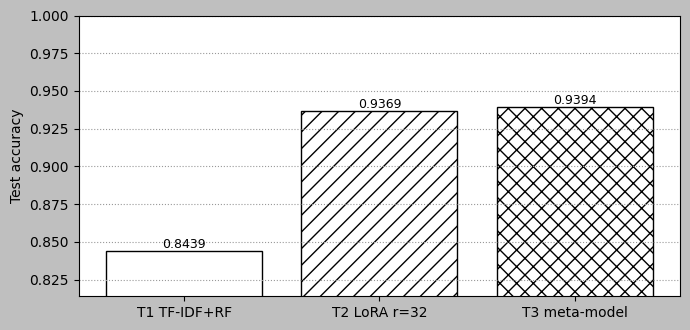

Wrote /content/drive/MyDrive/NLP_TermProject/results/report_numbers.tex
Wrote /content/drive/MyDrive/NLP_TermProject/results/report_examples.tex


In [ ]:
# @title Task 3c: final comparison (Task 1 vs Task 2 vs Task 3) + numbers file for the LaTeX report
t1 = require("task1_results.json", "Task 1"); t3 = require("task3_results.json", "Task 3a/3b")
t2s = require("t2_summary.json", "Task 2e"); trunc = require("t2_truncation.json", "Task 2a")
final = pd.DataFrame([
    {"Model": "Task 1: TF-IDF + RF", "Test accuracy": t3["t1_test_acc"]},
    {"Model": f"Task 2: LoRA r={t3['best_rank']} (best by holdout)", "Test accuracy": t3["t2_test_acc"]},
    {"Model": "Task 3: probability average (reference)", "Test accuracy": t3["avg_prob_test_acc"]},
    {"Model": "Task 3: LR meta-model on raw probabilities", "Test accuracy": t3["t3_raw_prob_test_acc"]},
    {"Model": "Task 3: LR meta-model on log-odds (main)", "Test accuracy": t3["t3_test_acc"]}])
final.to_csv(res_path("final_comparison.csv"), index=False)
display(final.style.format({"Test accuracy": "{:.4f}"}).hide(axis="index"))
print(f"Task 3 - Task 2 = {100*t3['delta_t3_minus_t2']:+.2f} pts, 95% CI [{100*t3['delta_ci95'][0]:+.2f}, {100*t3['delta_ci95'][1]:+.2f}], McNemar p = {t3['mcnemar_p']:.3g}")

fig, ax = plt.subplots(figsize=(7, 3.4))
lab = ["T1 TF-IDF+RF", f"T2 LoRA r={t3['best_rank']}", "T3 meta-model"]
vals = [t3["t1_test_acc"], t3["t2_test_acc"], t3["t3_test_acc"]]
bars = ax.bar(lab, vals, color="white", edgecolor="black", hatch=["", "//", "xx"])
for b_, v in zip(bars, vals):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.002, f"{v:.4f}", ha="center", fontsize=9)
ax.set_ylim(min(vals) - 0.03, 1.0); ax.set_ylabel("Test accuracy"); ax.grid(axis="y", linestyle=":", color="0.6")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "final_comparison.pdf")); plt.show()

# ---- \newcommand file consumed by report.tex (copy results/report_numbers.tex next to report.tex)
def f4(x): return f"{x:.4f}"
def pct(x): return f"{100*x:.1f}"
mac = {"TOneAcc": f4(t1["test_acc"]), "TOneAccHold": f4(t1["holdout_acc"]),
       "TOneAccFull": f4(t1.get("full_train_test_acc", float("nan"))),
       "TruncTrain": pct(trunc["train_truncated_frac"]), "TruncTest": pct(trunc["test_truncated_frac"]),
       "MedTokTrain": f"{trunc['train_median_tokens']:.0f}", "MedTokTest": f"{trunc['test_median_tokens']:.0f}",
       "BestRank": str(t3["best_rank"]), "TThreeAcc": f4(t3["t3_test_acc"]), "TThreeRawAcc": f4(t3["t3_raw_prob_test_acc"]),
       "AvgAcc": f4(t3["avg_prob_test_acc"]), "TThreeCV": f4(t3["holdout_cv_acc_mean"]),
       "TTwoBestAcc": f4(t3["t2_test_acc"]), "DeltaPts": f"{100*t3['delta_t3_minus_t2']:+.2f}",
       "DeltaLo": f"{100*t3['delta_ci95'][0]:+.2f}", "DeltaHi": f"{100*t3['delta_ci95'][1]:+.2f}",
       "McNemarP": f"{t3['mcnemar_p']:.3g}", "CoefRF": f"{t3['coef_rf']:.3f}", "CoefLora": f"{t3['coef_lora']:.3f}",
       "NLong": str(t3.get("n_long", "--")), "LongRF": f4(t3.get("long_rf", float("nan"))),
       "LongLora": f4(t3.get("long_lora", float("nan"))), "LongMeta": f4(t3.get("long_meta", float("nan"))),
       "NDis": str(t3.get("n_disagree", "--")), "DisRF": f4(t3.get("dis_rf", float("nan"))),
       "DisLora": f4(t3.get("dis_lora", float("nan"))), "DisMeta": f4(t3.get("dis_meta", float("nan")))}
names = {4: "Four", 8: "Eight", 16: "Sixteen", 32: "ThirtyTwo"}
for row in t2s["rows"]:
    key = "FullFT" if row["Model"].startswith("Full") else "Lora" + names.get(int(row["Model"].split("=")[1]), "X")
    mac[key + "Acc"] = f4(row["Test acc"]); mac[key + "Hold"] = f4(row["Holdout acc"]); mac[key + "Min"] = str(row["Minutes"])
if os.path.exists(res_path("task3_stretch_results.json")):
    mac["StretchAcc"] = f4(load_json("task3_stretch_results.json")["test_acc"])
with open(res_path("report_numbers.tex"), "w") as f:
    f.write("% auto-generated by Project9_IMDB_ver2.ipynb, Task 3c\n")
    for k, v in mac.items():
        f.write(f"\\newcommand{{\\{k}}}{{{v}}}\n")
print("Wrote", res_path("report_numbers.tex"))

# ---- qualitative examples as LaTeX (consumed by report.tex)
def tex_escape(t):
    rep = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_",
           "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}", "<": r"\textless{}", ">": r"\textgreater{}"}
    return "".join(rep.get(ch, ch) for ch in str(t).encode("ascii", "ignore").decode())
lines = []
for fname, cols in [("task2_qualitative.csv", ["p_pos"]), ("task3_qualitative.csv", ["p_rf", "p_lora", "p_meta"])]:
    if not os.path.exists(res_path(fname)):
        continue
    q = pd.read_csv(res_path(fname))
    for kind, grp in q.groupby("kind", sort=False):
        lines.append(f"\\paragraph{{Task {fname[4]}: {tex_escape(kind)}.}}")
        lines.append("\\begin{itemize}")
        for _, r_ in grp.head(2).iterrows():
            probs = ", ".join(f"{c} = {r_[c]:.3f}" for c in cols)
            lines.append(f"\\item \\textit{{gold {'positive' if r_['gold']==1 else 'negative'}; {tex_escape(probs)}}}. "
                         f"``{tex_escape(str(r_['text'])[:300])}''")
        lines.append("\\end{itemize}")
with open(res_path("report_examples.tex"), "w") as f:
    f.write("\n".join(lines) + "\n")
print("Wrote", res_path("report_examples.tex"))

**Task 3 discussion.** The question here is whether a model that only counts words knows anything a fine-tuned BERT doesn't. The meta-model's coefficients answer it directly: if the RF coefficient is near zero, the stack has decided TF-IDF adds nothing. The most plausible place for TF-IDF to help is long reviews, because BERT only reads the first 512 subwords while TF-IDF sees the whole text, and verdicts like "overall, 3/10" often sit at the end. The length breakdown in Task 3b tests exactly that. Any gain should be judged against the bootstrap interval and McNemar test rather than the raw difference, because on 25,000 reviews a 0.1-point change is only 25 reviews. The earlier notebook's stack scored 0.9344, *below* LoRA alone (0.9378), because it fitted the meta-model on training-set probabilities where both base models are overconfident. Fitting on the held-out 2,500 reviews is the fix.

### Task 3 stretch (optional): joint TF-IDF + LoRA model

This keeps the team's hybrid-fusion idea from the earlier notebook but removes the label leakage it had (the old version trained on "soft targets" built from the gold labels, which is why it reported 100% accuracy in one cell and 50% in another). Here the TF-IDF vector from Task 1 is projected to 256 dimensions and concatenated with the LoRA-BERT `[CLS]` vector, and the whole thing is trained end to end with ordinary cross-entropy on real labels. Set `RUN_STRETCH = True` in Section 0 to run it.

In [ ]:
# @title Task 3 stretch: joint TF-IDF + LoRA-BERT classifier (RUN_STRETCH)
if not RUN_STRETCH:
    print("Stretch skipped (RUN_STRETCH = False).")
else:
    import torch.nn as nn
    from transformers import AutoModel, AutoTokenizer, DataCollatorWithPadding, get_linear_schedule_with_warmup
    from peft import LoraConfig, TaskType, get_peft_model
    from torch.utils.data import DataLoader, Dataset
    D = get_data(); set_seed(); free_memory()
    with open(os.path.join(CKPT_DIR, "t1_tfidf_rf.pkl"), "rb") as f:
        vec, _ = pickle.load(f)                                    # fitted on the core split only
    r_s = require("t2_summary.json", "Task 2e")["best_rank"]
    tk = AutoTokenizer.from_pretrained(MODEL_NAME); coll = DataCollatorWithPadding(tk)

    class JointDS(Dataset):
        def __init__(self, texts, labels):
            self.enc = {k: list(v) for k, v in tk(texts, truncation=True, max_length=MAX_LEN).items()}
            self.X = vec.transform(texts).tocsr().astype(np.float32); self.y = np.asarray(labels)
        def __len__(self): return len(self.y)
        def __getitem__(self, i):
            d = {k: self.enc[k][i] for k in self.enc}; d["labels"] = int(self.y[i]); d["row"] = i; return d
    def make_collate(ds):
        def _c(batch):
            rows = [b.pop("row") for b in batch]; out = coll(batch)
            out["tfidf"] = torch.from_numpy(ds.X[rows].toarray()); return out
        return _c

    class Joint(nn.Module):
        def __init__(self):
            super().__init__()
            bert = AutoModel.from_pretrained(MODEL_NAME)
            self.bert = get_peft_model(bert, LoraConfig(task_type=TaskType.FEATURE_EXTRACTION, r=r_s, lora_alpha=2 * r_s,
                                                       lora_dropout=0.1, target_modules=["query", "value"]))
            hid = bert.config.hidden_size                          # 768 for bert-base
            self.proj = nn.Sequential(nn.Linear(len(vec.vocabulary_), 256), nn.ReLU(), nn.Dropout(0.3))
            self.head = nn.Sequential(nn.LayerNorm(hid + 256), nn.Dropout(0.1), nn.Linear(hid + 256, 2))
        def forward(self, input_ids, attention_mask, tfidf, token_type_ids=None):
            h = self.bert(input_ids=input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids).last_hidden_state[:, 0]
            return self.head(torch.cat([h, self.proj(tfidf)], dim=-1))

    tr, te = JointDS(D["core_text"], D["y_core"]), JointDS(D["test_text"], D["y_test"])
    model = Joint().to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=LORA_LR, weight_decay=WEIGHT_DECAY)
    g = torch.Generator(); g.manual_seed(SEED)
    dl = DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True, collate_fn=make_collate(tr), generator=g)
    sched = get_linear_schedule_with_warmup(opt, 0, len(dl) * EPOCHS)
    scaler = _scaler(DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
    lossf = nn.CrossEntropyLoss(); t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); tot = 0
        for step, b in enumerate(dl):
            b = {k: v.to(DEVICE) for k, v in b.items()}; yb = b.pop("labels")
            with autocast_ctx():
                loss = lossf(model(**b).float(), yb)
            scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); tot += loss.item()
            if step % 400 == 0: print(f"  epoch {ep+1} step {step}/{len(dl)} loss {tot/(step+1):.4f}")
    model.eval(); preds = []
    with torch.no_grad():
        for b in DataLoader(te, batch_size=64, collate_fn=make_collate(te)):
            b = {k: v.to(DEVICE) for k, v in b.items()}; b.pop("labels")
            with autocast_ctx():
                preds.append(torch.softmax(model(**b).float(), -1)[:, 1].cpu())
    p = torch.cat(preds).numpy()
    st = {"rank": r_s, "test_acc": accuracy(D["y_test"], p), "trainable_params": int(sum(x.numel() for x in params)),
          "minutes": round((time.time() - t0) / 60, 1)}
    save_json(st, "task3_stretch_results.json"); print(st)
    del model, opt; free_memory()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  epoch 1 step 0/1407 loss 1.1068
  epoch 1 step 400/1407 loss 0.3229
  epoch 1 step 800/1407 loss 0.2793
  epoch 1 step 1200/1407 loss 0.2561
  epoch 2 step 0/1407 loss 0.0533
  epoch 2 step 400/1407 loss 0.1029
  epoch 2 step 800/1407 loss 0.1067
  epoch 2 step 1200/1407 loss 0.1053
  epoch 3 step 0/1407 loss 0.0551
  epoch 3 step 400/1407 loss 0.0462
  epoch 3 step 800/1407 loss 0.0437
  epoch 3 step 1200/1407 loss 0.0427
{'rank': 32, 'test_acc': 0.93488, 'trainable_params': 6304002, 'minutes': 27.9}


## Outputs written to Drive (`BASE_DIR/results`)

| File | Made by | Contents |
|---|---|---|
| `task1_results.json`, `t1_hold_prob.npy`, `t1_test_prob.npy` | Task 1 | accuracy, RF probabilities |
| `t2_truncation.json`, `t2_test_token_lengths.npy` | Task 2a | truncation statistics |
| `t2_lora_r{4,8,16,32}_*`, `t2_full_ft_*` | Task 2c/2d | per-epoch history, probabilities, parameter counts |
| `task2_results.csv`, `t2_summary.json`, `figures/task2_*.pdf` | Task 2e | rank table, best rank, plots |
| `task2_qualitative.csv`, `task3_qualitative.csv` | 2f / 3b | example reviews for the report |
| `task3_results.json`, `task3_breakdown.csv`, `final_comparison.csv` | Task 3 | meta-model, significance tests, analysis |
| `report_numbers.tex` | Task 3c | every number the LaTeX report prints |

Fixed seed everywhere: `SEED = 42` (data split, RF, model init, data order, bootstrap).